<h1 style="text-align: center;">Ciencia de Datos en Turismo
</h3>
<h3 style="text-align: center;"> Práctica 1b </h3>
<h3 style="text-align: center;"> Octubre 2026 </h3>

## Ejercicio 1 

En el siguiente enlace se encuentran dos bases de datos: [Madrid att.csv](https://ulpgc-my.sharepoint.com/:x:/g/personal/juan_hernandez_ulpgc_es/IQCDwsvwAJHMTbjj6aWjT9cSAUH8E38DSryiL7VJaYWaNTQ?e=JPji0A) y [Madrid reviews.csv](https://ulpgc-my.sharepoint.com/:x:/g/personal/juan_hernandez_ulpgc_es/IQDlTCH5csHrQqvs-B9R423_AbelpaiTngxoLEZ1FMEFt9s?e=Miwnb3). 

- La base de datos **Madrid att.csv** contiene 673 atracciones de Madrid con su identificador (id atr), número de revisiones recibidas, dirección, posición en una lista ordenada de atracciones en Madrid y categorías de atracciones que la identifican (tags).

- La base de datos **Madrid reviews.csv** contiene 125674 revisiones de las atracciones de Madrid incluyendo el ID del revisor y atracción (id atr), rating de la atracción (en valores enteros del 1 al 5), fecha de la revisión (entre 2006 y 2018) y otra información que identifica al revisor.

Se quieren determinar los factores que influyen en el rating obtenido. Dicho de otra manera, el objetivo es ajustar lo mejor posible la siguiente función f:

$$ f(x_{i1}, x_{i2}, ..., x_{id}) = r_i \quad \forall i \in \{1, 2, ..., n\} $$

siendo $ r_i $ el rating de la atracción $ i $-ésima y $ x_{ij} $ las variables explicativas del modelo. El trabajo a realizar es el siguiente:

**(a)**	Determinación de la variable target y las explicativas.

**(b)**	Limpieza y análisis exploratorio de los datos. Se pueden realizar visualizaciones, test de hipótesis y clustering o aplicación de técnicas de reducción de la dimensionalidad.




In [2]:
import pandas as pd
import csv

# 1. Cargar los datos indicando a pandas que ignore las comillas conflictivas
df_att = pd.read_csv('Madrid_att(in).csv', sep=';', quoting=csv.QUOTE_NONE)
df_reviews = pd.read_csv('Madrid_reviews(in).csv', sep=';', quoting=csv.QUOTE_NONE)

# 2. Limpiar las comillas (") y las comas sueltas (,) que traían los archivos por error
# Limpiamos las atracciones
df_att = df_att.replace('"', '', regex=True).replace(',+$', '', regex=True)
df_att.columns = df_att.columns.str.replace('"', '').str.replace(',+$', '', regex=True)

# Limpiamos las revisiones
df_reviews = df_reviews.replace('"', '', regex=True).replace(',+$', '', regex=True)
df_reviews.columns = df_reviews.columns.str.replace('"', '').str.replace(',+$', '', regex=True)

# Visualizar las bases ya limpias y correctamente estructuradas
display(df_att.head(10))
display(df_reviews.head(10))

,,id_atr,nombre_atr,num_rev_atr,address,pos,tags
0,1,d191050,Retiro Park (Parque del Retiro),47778,Between C. Alfonso XII and Avenida de Menendez...,#1 of 811 things to do in Madrid,"Nature & Parks, Sights & Landmarks, Bodies of ..."
1,2,d190143,Prado National Museum,49908,"Calle Ruiz de Alarcon 23, 28014 Madrid, Spain",#2 of 811 things to do in Madrid,"Museums, Specialty Museums"
2,3,d198867,Museo Nacional Thyssen-Bornemisza,14687,"Paseo Prado 8, 28048 Madrid, Spain",#3 of 811 things to do in Madrid,"Museums, Specialty Museums"
3,4,d796251,Stadio Santiago Bernabeu,19879,"Avenida de Concha Espina 1 | Bernabeu Stadium,...",#4 of 811 things to do in Madrid,"Sights & Landmarks, Arenas & Stadiums"
4,5,d190146,Royal Palace of Madrid,30186,"Calle Bailen, 28071 Madrid, Spain",#5 of 811 things to do in Madrid,"Museums, Sights & Landmarks, Art Museums, Hist..."
5,6,d190152,Museo Nacional Centro de Arte Reina Sofia,14324,"Calle de Santa Isabel 52, 28012 Madrid, Spain",#6 of 811 things to do in Madrid,"Museums, Art Museums"
6,7,d246516,Gran Via,11729,"Street Gran Via, 28013 Madrid, Spain",#7 of 811 things to do in Madrid,"Sights & Landmarks, Points of Interest & Landm..."
7,8,d244303,Templo de Debod,11672,"Calle Ferraz 1, 28008 Madrid, Spain",#8 of 811 things to do in Madrid,"Sights & Landmarks, Historic Sites"
8,9,d190142,Plaza Mayor,22546,"Calle Gerona 4, 28012 Madrid, Spain",#9 of 811 things to do in Madrid,"Sights & Landmarks, Points of Interest & Landm..."
9,10,d1520183,Mercado San Miguel,26781,"Plaza San Miguel, 28005 Madrid, Spain",#10 of 811 things to do in Madrid,"Shopping, Flea & Street Markets"


,,user_id,id_atr,rating_rev,date_rev,leng,usr.name,usr.login,since,hometown,info.usr,tag.usr
0,1,1E4BA1FBFB6D49508A381F5E78E633F1,d592827,5,2017-10-11,en,mercedes n,mercedesn,TripAdvisor member since 2011,"From Catalonia, Spain","135 Contributions, 40 Cities visited, 23 Helpf...","Art and Architecture Lover, Foodie, Urban Expl..."
1,2,FC1C559F644A6D700CAAC522B0027DA1,d592827,4,2017-08-24,en,Miriam67,Miriam67,TripAdvisor member since 2008,"50-64 woman from Malaga, Spain","48 Contributions, 273 Cities visited, 13 Helpf...","Art and Architecture Lover, Foodie, History Buff"
2,3,F32F65328FB68C92FF7D94BDE3D37CC5,d592827,5,2017-08-16,en,Monicalventura,Monicalventura,TripAdvisor member since 2014,From San francisco,"37 Contributions, 12 Cities visited, 8 Helpful...",NA
3,4,00925F3454F45A577B17C20C400F3540,d592827,5,2017-07-07,en,Kit M,413kitm,TripAdvisor member since 2014,NaN,"18 Contributions, 7 Cities visited, 1 Helpful ...",NA
4,5,83462D5B5273D9952C78D50C0F48528D,d592827,5,2017-06-24,en,521alberth,521alberth,TripAdvisor member since 2013,NaN,"48 Contributions, 193 Cities visited, 14 Helpf...","Art and Architecture Lover, Foodie, Urban Expl..."
5,6,8DC7D0CDD85BAD91F37DCBFC9E03B9C6,d592827,5,2017-05-21,en,RichNY1,RichNY1,TripAdvisor member since 2006,"From New York City, New York","84 Contributions, 130 Cities visited, 75 Helpf...","Urban Explorer, Like a Local, History Buff, 60..."
6,7,E323632A70618B68366FEF04BBDDDCB9,d592827,4,2017-04-13,en,Cristobal P,768cristobalp,TripAdvisor member since 2014,"50-64 man from Santiago, Chile","22 Contributions, 346 Cities visited, 11 Helpf...","Foodie, Urban Explorer, Nature Lover, 60+ Trav..."
7,8,4FF815E08B67B5FE918EDB965CEA41EB,d592827,4,2017-01-08,en,MataHari2013,MataHari2013,TripAdvisor member since 2013,"From Wiesbaden, Hessen, Germany","27 Contributions, 231 Cities visited, 11 Helpf...","Art and Architecture Lover, Vegetarian, Foodie..."
8,9,7A1D2FF3EF6E4DC0C648FE6C0FF24B6F,d592827,5,2016-11-23,en,Carlos B,393CarlosB,TripAdvisor member since 2013,"From Jersey City, New Jersey","24 Contributions, 10 Cities visited, 9 Helpful...","Shopping Fanatic, Peace and Quiet Seeker, Luxu..."
9,10,58CE37A49BD1E83AF02F090F0D41FFD0,d592827,4,2016-11-02,en,nmartinmarcus25,nmartinmarcus25,TripAdvisor member since 2016,"50-64 woman from Garrucha, Spain","8 Contributions, 2 Cities visited",NA


In [3]:
import pandas as pd
import csv
import re
import time
from geopy.geocoders import Nominatim
from geopy.exc import GeocoderTimedOut

# Asumimos que df_att ya está cargado en este punto...

# 1. Aseguramos que la columna existe (si no, la crea vacía)
if 'codigo_postal' not in df_att.columns:
    df_att['codigo_postal'] = None

# 2. Extraer CP con Regex SOLO en las filas donde falte (para no pisar datos guardados)
mask_nulos = df_att['codigo_postal'].isna()
df_att.loc[mask_nulos, 'codigo_postal'] = df_att.loc[mask_nulos, 'address'].str.extract(r'\b(28\d{3})\b')[0]

faltantes_iniciales = df_att['codigo_postal'].isna().sum()
print(f"Códigos postales extraídos con Regex/Guardados. Faltan por rellenar: {faltantes_iniciales}")

# 3. Rellenar usando Geopy con doble intento
geolocator = Nominatim(user_agent="turismo_madrid_ds_project")

def obtener_cp_desde_texto(texto):
    """Función genérica para buscar en OpenStreetMap a partir de cualquier texto"""
    if pd.isna(texto):
        return None
    try:
        texto_limpio = str(texto).split('|')[0].strip()
        location = geolocator.geocode(texto_limpio, addressdetails=True, timeout=10)
        
        if location and 'address' in location.raw:
            cp = location.raw['address'].get('postcode')
            if cp:
                # Validar que empiece por 28 y tenga 5 dígitos, por seguridad
                match = re.search(r'\b(28\d{3})\b', str(cp))
                if match:
                    return match.group(1)
    except Exception:
        pass # Ignorar errores de conexión
    return None

# Filtramos estrictamente las que NO tienen código postal tras el regex
filas_sin_cp = df_att[df_att['codigo_postal'].isna()]

print("Iniciando búsqueda online (dirección y nombre)...")

for index, row in filas_sin_cp.iterrows():
    # INTENTO 1: Buscar por la dirección
    nuevo_cp = obtener_cp_desde_texto(row['address'])
    time.sleep(1) # Pausa obligatoria de la API
    
    # INTENTO 2: Si falla la dirección, buscar por el nombre de la atracción
    if not nuevo_cp:
        # Le añadimos ", Madrid" para que el mapa sepa dónde buscar
        busqueda_por_nombre = str(row['nombre_atr']) + ", Madrid"
        nuevo_cp = obtener_cp_desde_texto(busqueda_por_nombre)
        time.sleep(1) # Pausa obligatoria tras el segundo intento
        
    # Si cualquiera de los dos intentos funcionó, lo guardamos
    if nuevo_cp:
        df_att.at[index, 'codigo_postal'] = nuevo_cp

# Revisamos el resultado final
faltantes_finales = df_att['codigo_postal'].isna().sum()
print(f"\nProceso terminado. Códigos postales faltantes ahora: {faltantes_finales}")

# Mostrar una muestra de resultados
display(df_att[['nombre_atr', 'address', 'codigo_postal']].head(10))

Códigos postales extraídos con Regex/Guardados. Faltan por rellenar: 163
Iniciando búsqueda online (dirección y nombre)...

Proceso terminado. Códigos postales faltantes ahora: 45


,nombre_atr,address,codigo_postal
0,Retiro Park (Parque del Retiro),Between C. Alfonso XII and Avenida de Menendez...,28010
1,Prado National Museum,"Calle Ruiz de Alarcon 23, 28014 Madrid, Spain",28014
2,Museo Nacional Thyssen-Bornemisza,"Paseo Prado 8, 28048 Madrid, Spain",28048
3,Stadio Santiago Bernabeu,"Avenida de Concha Espina 1 | Bernabeu Stadium,...",28036
4,Royal Palace of Madrid,"Calle Bailen, 28071 Madrid, Spain",28071
5,Museo Nacional Centro de Arte Reina Sofia,"Calle de Santa Isabel 52, 28012 Madrid, Spain",28012
6,Gran Via,"Street Gran Via, 28013 Madrid, Spain",28013
7,Templo de Debod,"Calle Ferraz 1, 28008 Madrid, Spain",28008
8,Plaza Mayor,"Calle Gerona 4, 28012 Madrid, Spain",28012
9,Mercado San Miguel,"Plaza San Miguel, 28005 Madrid, Spain",28005


Permite transformar una dirección en texto libre en una variable espacial estructurada para poder analizar la influencia de la ubicación geográfica.

In [4]:
# Extraer los números de cada categoría utilizando expresiones regulares
df_reviews['Contributions'] = df_reviews['info.usr'].str.extract(r'(\d+)\s*Contribution').astype(float)
df_reviews['Cities_visited'] = df_reviews['info.usr'].str.extract(r'(\d+)\s*Cit').astype(float)
df_reviews['Helpful_votes'] = df_reviews['info.usr'].str.extract(r'(\d+)\s*Helpful').astype(float)
df_reviews['Photos'] = df_reviews['info.usr'].str.extract(r'(\d+)\s*Photo').astype(float)

# Rellenar los valores nulos (NaN) con 0 en todas las nuevas columnas, tal como indicaste para las fotos
cols_info = ['Contributions', 'Cities_visited', 'Helpful_votes', 'Photos']
df_reviews[cols_info] = df_reviews[cols_info].fillna(0).astype(int)

# Opcional: Eliminar la columna original de texto ya que la información ha sido extraída
df_reviews = df_reviews.drop(columns=['info.usr'])

# Visualizar el resultado
display(df_reviews[['user_id'] + cols_info].head())

,user_id,Contributions,Cities_visited,Helpful_votes,Photos
0,1E4BA1FBFB6D49508A381F5E78E633F1,135,40,23,35
1,FC1C559F644A6D700CAAC522B0027DA1,48,273,13,1
2,F32F65328FB68C92FF7D94BDE3D37CC5,37,12,8,0
3,00925F3454F45A577B17C20C400F3540,18,7,1,0
4,83462D5B5273D9952C78D50C0F48528D,48,193,14,58


Evita perder opiniones de turistas esporádicos y permite que el modelo distinga con rigor entre usuarios novatos y expertos.

In [5]:
# Extraemos los dígitos que van justo después del símbolo '#'
df_att['pos'] = df_att['pos'].str.extract(r'#(\d+)').astype(int)

# Visualizamos para comprobar el cambio
display(df_att[['nombre_atr', 'pos']].head(15))

,nombre_atr,pos
0,Retiro Park (Parque del Retiro),1
1,Prado National Museum,2
2,Museo Nacional Thyssen-Bornemisza,3
3,Stadio Santiago Bernabeu,4
4,Royal Palace of Madrid,5
5,Museo Nacional Centro de Arte Reina Sofia,6
6,Gran Via,7
7,Templo de Debod,8
8,Plaza Mayor,9
9,Mercado San Miguel,10


Convierte una frase descriptiva en un valor numérico continuo para medir cuantitativamente el prestigio y posicionamiento de la atracción.

In [6]:
# Cuenta cuántas celdas en 'since' empiezan por 'TripAdvisor member'
cantidad = df_reviews['since'].str.startswith('TripAdvisor member').sum()
print(f"Empiezan por TripAdvisor member: {cantidad}")

Empiezan por TripAdvisor member: 125764


Permite cuantificar de forma objetiva la veteranía y experiencia del usuario dentro de la plataforma.

In [7]:
# Extraemos solo los 4 dígitos del año y lo convertimos a número
df_reviews['since_year'] = df_reviews['since'].str.extract(r'(\d{4})').astype(int)

# Si quieres ver cómo queda:
display(df_reviews[['since', 'since_year']].head())

,since,since_year
0,TripAdvisor member since 2011,2011
1,TripAdvisor member since 2008,2008
2,TripAdvisor member since 2014,2014
3,TripAdvisor member since 2014,2014
4,TripAdvisor member since 2013,2013


In [8]:
# Lista de variables explicativas (features)
variables_explicativas = [
    'tags',          # Características de la atracción
    'pos',           # Ranking de la atracción
    'num_rev_atr',   # Popularidad de la atracción
    'tag.usr',       # Preferencias del usuario
    'Contributions', # Nivel de contribución del usuario
    'Cities_visited', # Nivel de experiencia del usuario
    'Helpful_votes', # Nivel de experiencia del usuario
    'Photos',        # Nivel de experiencia del usuario
    'codigo_postal', # Ubicación de la atracción
    'hometown',      # Origen del usuario
    'since_year',    # Antigüedad del usuario
    'leng',          # Idioma / Perfil cultural
    'date_rev'       # Contexto temporal (estacionalidad)
]

# Variable objetivo
variable_target = 'rating_rev'

In [9]:
# Unir df_reviews (base) con df_att (datos a añadir) usando 'id_atr'
df_merged = pd.merge(df_reviews, df_att, on='id_atr', how='left')

# Comprobar el tamaño del nuevo DataFrame combinado y sus columnas
print(f"Dimensiones del dataset final: {df_merged.shape}")
print("Columnas disponibles:", df_merged.columns.tolist())

# Visualizar el resultado
display(df_merged.head(5))

Dimensiones del dataset final: (125764, 23)
Columnas disponibles: ['_x', 'user_id', 'id_atr', 'rating_rev', 'date_rev', 'leng', 'usr.name', 'usr.login', 'since', 'hometown', 'tag.usr', 'Contributions', 'Cities_visited', 'Helpful_votes', 'Photos', 'since_year', '_y', 'nombre_atr', 'num_rev_atr', 'address', 'pos', 'tags', 'codigo_postal']


,_x,user_id,id_atr,rating_rev,date_rev,leng,usr.name,usr.login,since,hometown,...,Helpful_votes,Photos,since_year,_y,nombre_atr,num_rev_atr,address,pos,tags,codigo_postal
0,1,1E4BA1FBFB6D49508A381F5E78E633F1,d592827,5,2017-10-11,en,mercedes n,mercedesn,TripAdvisor member since 2011,"From Catalonia, Spain",...,23,35,2011,26,Barrio de Salamanca,1676,"Jose Ortega y Gasset, 8 - patio, 28006 Madrid,...",26,"Sights & Landmarks, Other, Neighborhoods, Hist...",28006
1,2,FC1C559F644A6D700CAAC522B0027DA1,d592827,4,2017-08-24,en,Miriam67,Miriam67,TripAdvisor member since 2008,"50-64 woman from Malaga, Spain",...,13,1,2008,26,Barrio de Salamanca,1676,"Jose Ortega y Gasset, 8 - patio, 28006 Madrid,...",26,"Sights & Landmarks, Other, Neighborhoods, Hist...",28006
2,3,F32F65328FB68C92FF7D94BDE3D37CC5,d592827,5,2017-08-16,en,Monicalventura,Monicalventura,TripAdvisor member since 2014,From San francisco,...,8,0,2014,26,Barrio de Salamanca,1676,"Jose Ortega y Gasset, 8 - patio, 28006 Madrid,...",26,"Sights & Landmarks, Other, Neighborhoods, Hist...",28006
3,4,00925F3454F45A577B17C20C400F3540,d592827,5,2017-07-07,en,Kit M,413kitm,TripAdvisor member since 2014,NaN,...,1,0,2014,26,Barrio de Salamanca,1676,"Jose Ortega y Gasset, 8 - patio, 28006 Madrid,...",26,"Sights & Landmarks, Other, Neighborhoods, Hist...",28006
4,5,83462D5B5273D9952C78D50C0F48528D,d592827,5,2017-06-24,en,521alberth,521alberth,TripAdvisor member since 2013,NaN,...,14,58,2013,26,Barrio de Salamanca,1676,"Jose Ortega y Gasset, 8 - patio, 28006 Madrid,...",26,"Sights & Landmarks, Other, Neighborhoods, Hist...",28006


In [10]:
# Crear una copia limpia para no alterar el DataFrame original
df_ml = df_merged.copy()

def aplicar_one_hot_top_n(df, columna, prefijo, top_n=15):
    # Rellenar nulos
    s = df[columna].fillna('')
    
    # Extraer y contar las etiquetas más frecuentes
    todas_etiquetas = s.str.split(',').explode().str.strip()
    todas_etiquetas = todas_etiquetas[todas_etiquetas != '']
    top_etiquetas = todas_etiquetas.value_counts().nlargest(top_n).index.tolist()
    
    # Crear una nueva columna binaria (0 o 1) por cada etiqueta principal
    for etiqueta in top_etiquetas:
        # Formatear el nombre de la columna (ej. 'tag_atr_nature_&_parks')
        nombre_col = f"{prefijo}_{etiqueta.replace(' ', '_').lower()}"
        df[nombre_col] = s.str.contains(etiqueta, regex=False, na=False).astype(int)
        
    return df

# 1. Aplicar a las características de la atracción (Top 15 etiquetas)
df_ml = aplicar_one_hot_top_n(df_ml, 'tags', 'tag_atr', top_n=15)

# 2. Aplicar a los perfiles del usuario (Top 15 etiquetas)
df_ml = aplicar_one_hot_top_n(df_ml, 'tag.usr', 'tag_usr', top_n=15)

# 3. Eliminar las columnas de texto con comas originales
df_ml = df_ml.drop(columns=['tags', 'tag.usr'])

# Comprobar las nuevas columnas generadas
print(df_ml.columns.tolist())
display(df_ml.head(3))

['_x', 'user_id', 'id_atr', 'rating_rev', 'date_rev', 'leng', 'usr.name', 'usr.login', 'since', 'hometown', 'Contributions', 'Cities_visited', 'Helpful_votes', 'Photos', 'since_year', '_y', 'nombre_atr', 'num_rev_atr', 'address', 'pos', 'codigo_postal', 'tag_atr_sights_&_landmarks', 'tag_atr_museums', 'tag_atr_architectural_buildings_more', 'tag_atr_nature_&_parks', 'tag_atr_specialty_museums', 'tag_atr_points_of_interest_&_landmarks', 'tag_atr_historic_sites', 'tag_atr_gardens', 'tag_atr_bodies_of_water', 'tag_atr_art_museums', 'tag_atr_shopping', 'tag_atr_flea_&_street_markets', 'tag_atr_arenas_&_stadiums', 'tag_atr_architectural_buildings', 'tag_atr_history_museums', 'tag_usr_na', 'tag_usr_foodie', 'tag_usr_urban_explorer', 'tag_usr_art_and_architecture_lover', 'tag_usr_history_buff', 'tag_usr_like_a_local', 'tag_usr_nature_lover', 'tag_usr_family_vacationer', 'tag_usr_thrill_seeker', 'tag_usr_peace_and_quiet_seeker', 'tag_usr_shopping_fanatic', 'tag_usr_beach_goer', 'tag_usr_thrift

,_x,user_id,id_atr,rating_rev,date_rev,leng,usr.name,usr.login,since,hometown,...,tag_usr_like_a_local,tag_usr_nature_lover,tag_usr_family_vacationer,tag_usr_thrill_seeker,tag_usr_peace_and_quiet_seeker,tag_usr_shopping_fanatic,tag_usr_beach_goer,tag_usr_thrifty_traveler,tag_usr_60+_traveler,tag_usr_nightlife_seeker
0,1,1E4BA1FBFB6D49508A381F5E78E633F1,d592827,5,2017-10-11,en,mercedes n,mercedesn,TripAdvisor member since 2011,"From Catalonia, Spain",...,1,0,0,0,0,0,0,0,0,0
1,2,FC1C559F644A6D700CAAC522B0027DA1,d592827,4,2017-08-24,en,Miriam67,Miriam67,TripAdvisor member since 2008,"50-64 woman from Malaga, Spain",...,0,0,0,0,0,0,0,0,0,0
2,3,F32F65328FB68C92FF7D94BDE3D37CC5,d592827,5,2017-08-16,en,Monicalventura,Monicalventura,TripAdvisor member since 2014,From San francisco,...,0,0,0,0,0,0,0,0,0,0


C:\Users\enriq\AppData\Local\Temp\ipykernel_2072\841840001.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_ml, x='rating_rev', palette='viridis')


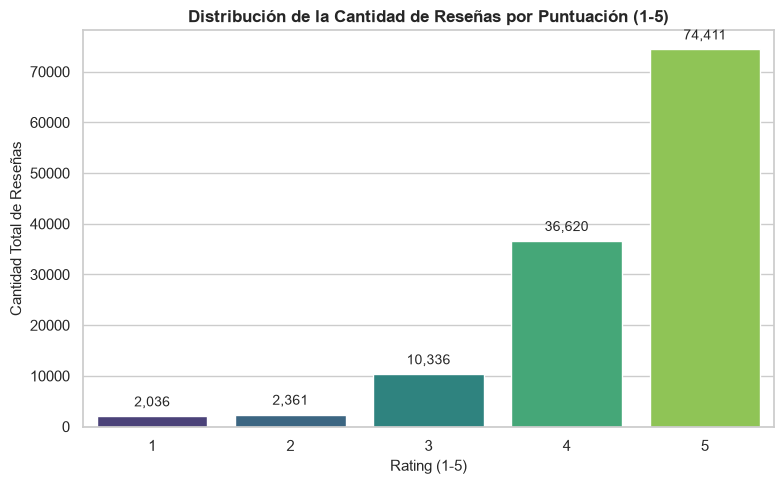

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño y estilo del gráfico
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras contando las frecuencias de cada rating
ax = sns.countplot(data=df_ml, x='rating_rev', palette='viridis')

# Añadir etiquetas y título
plt.title('Distribución de la Cantidad de Reseñas por Puntuación (1-5)', fontweight='bold', fontsize=12)
plt.xlabel('Rating (1-5)', fontsize=11)
plt.ylabel('Cantidad Total de Reseñas', fontsize=11)

# Añadir el número exacto sobre cada barra para ver la diferencia real
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(f'{int(altura):,}', 
                (p.get_x() + p.get_width() / 2., altura), 
                ha='center', va='bottom', 
                fontsize=10, xytext=(0, 5), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

Demuestra que existe un fuerte desbalance de clases: más del 80% de las opiniones son muy positivas (notas 4 y 5), mientras que las valoraciones negativas (1, 2 y 3) son testimoniales. Esto evidencia que el Accuracy general será una métrica engañosa y obliga a utilizar técnicas de balanceo en el modelado.

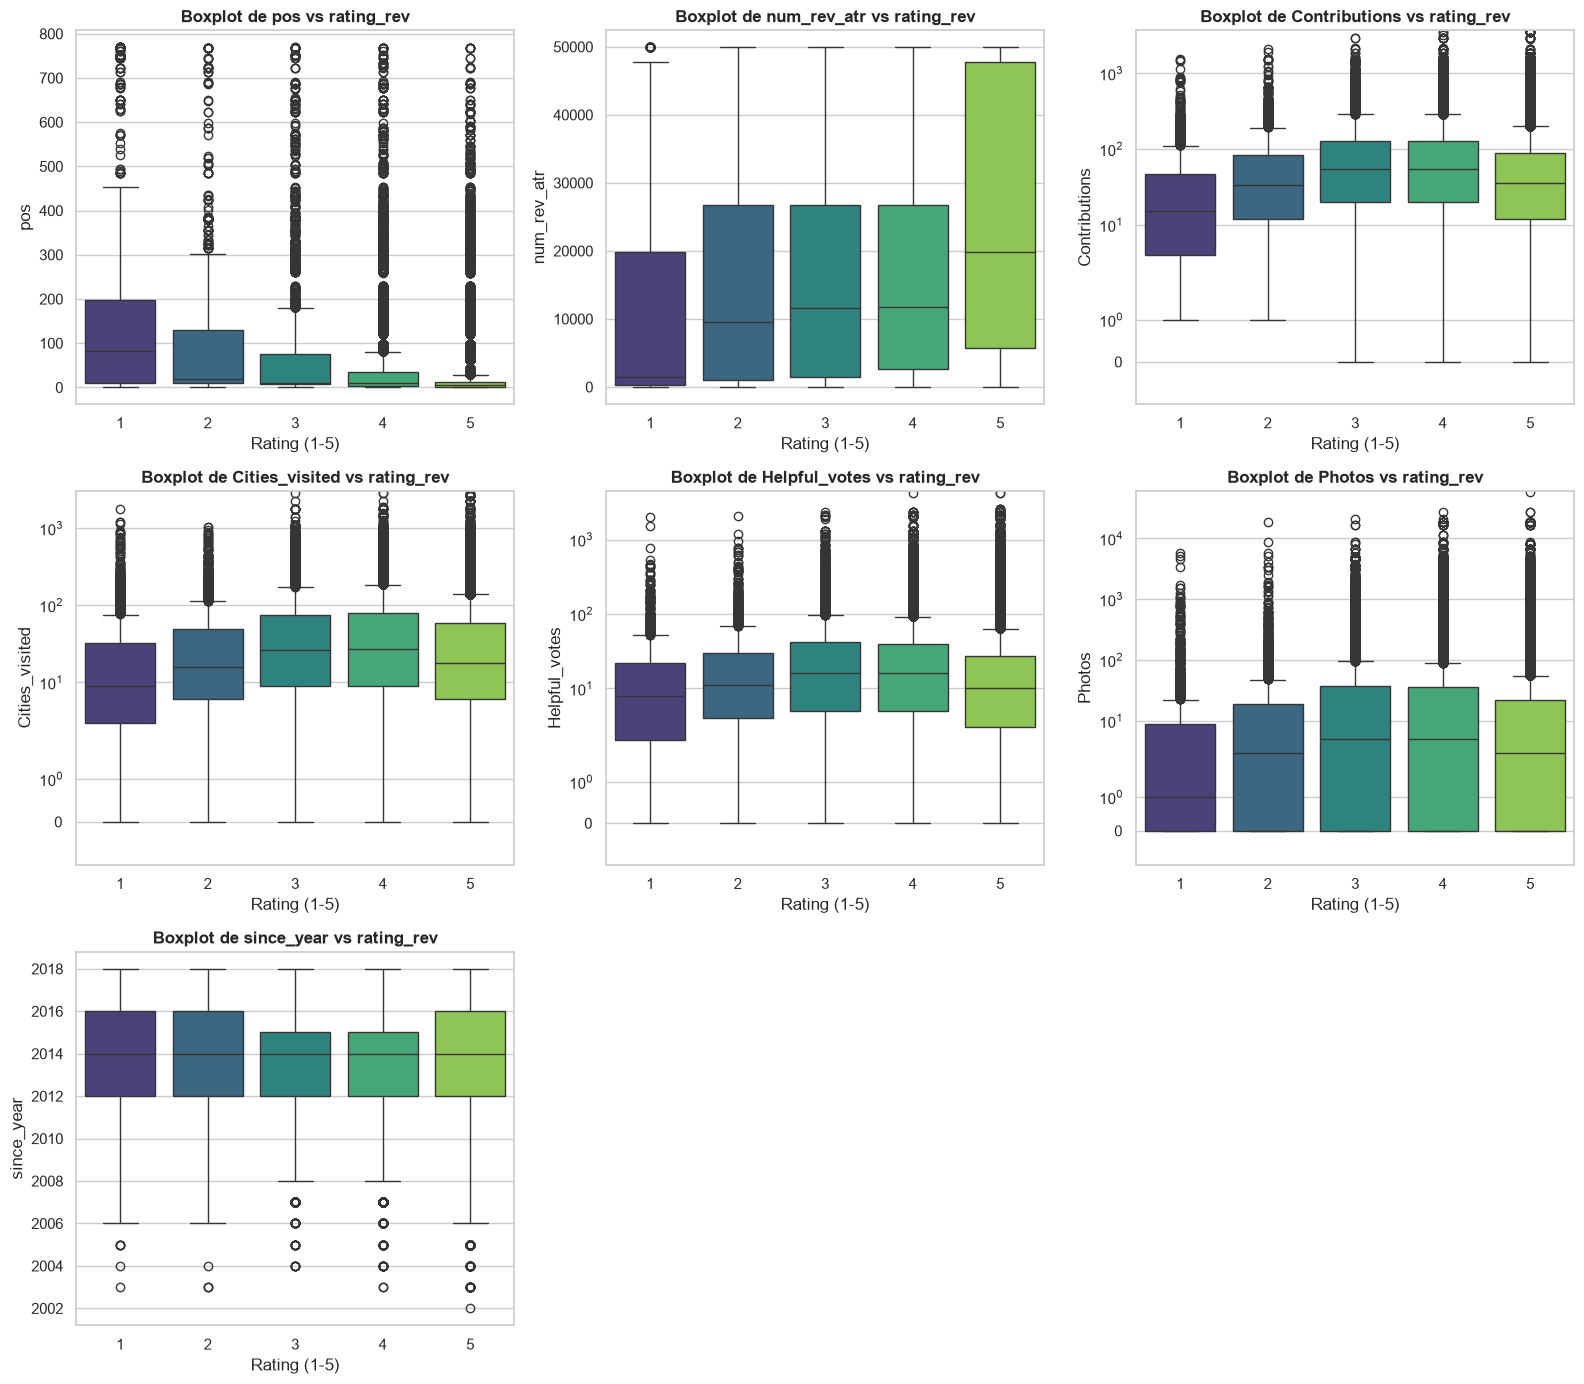

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Definir solo las variables numéricas explicativas para los boxplots
variables_numericas = [
    'pos', 'num_rev_atr', 'Contributions', 'Cities_visited', 
    'Helpful_votes', 'Photos', 'since_year'
]

# Configurar el lienzo (subplots de 3x3)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.flatten()

# Generar un boxplot para cada variable numérica segmentado por el rating usando df_ml
for i, var in enumerate(variables_numericas):
    sns.boxplot(x='rating_rev', y=var, data=df_ml, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Boxplot de {var} vs rating_rev', fontweight='bold')
    axes[i].set_xlabel('Rating (1-5)')
    axes[i].set_ylabel(var)
    
    # Aplicar escala logarítmica a variables con alta dispersión y forzar inicio en 0
    if var in ['Contributions', 'Helpful_votes', 'Photos', 'Cities_visited']:
        axes[i].set_yscale('symlog')
        axes[i].set_ylim(bottom=-1)

# Eliminar los gráficos vacíos sobrantes en la cuadrícula de 3x3
for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Muestran que las métricas de experiencia del usuario (Contributions, Photos, etc.) presentan distribuciones prácticamente idénticas en todas las notas, confirmando que la veteranía del visitante no determina la satisfacción. Solo las variables ligadas a la atracción (especialmente un mejor ranking en pos) muestran cierta capacidad para contener las valoraciones negativas.

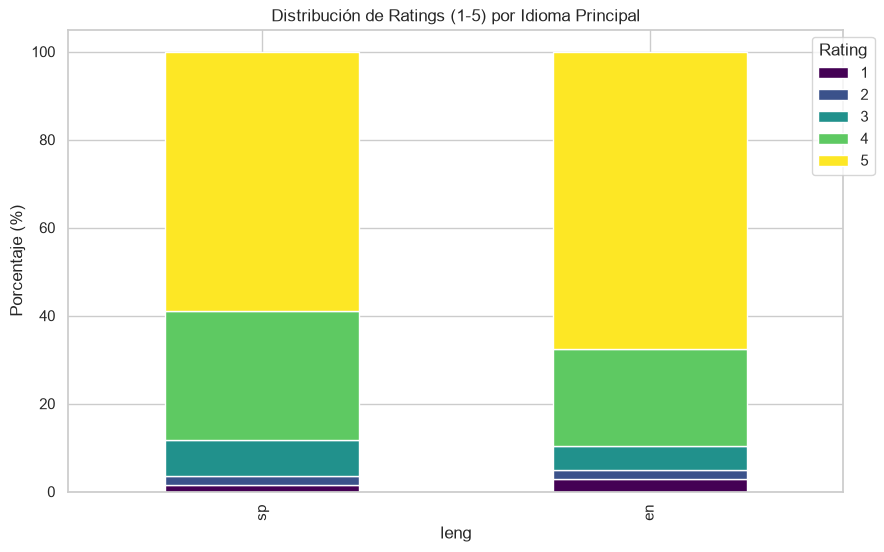

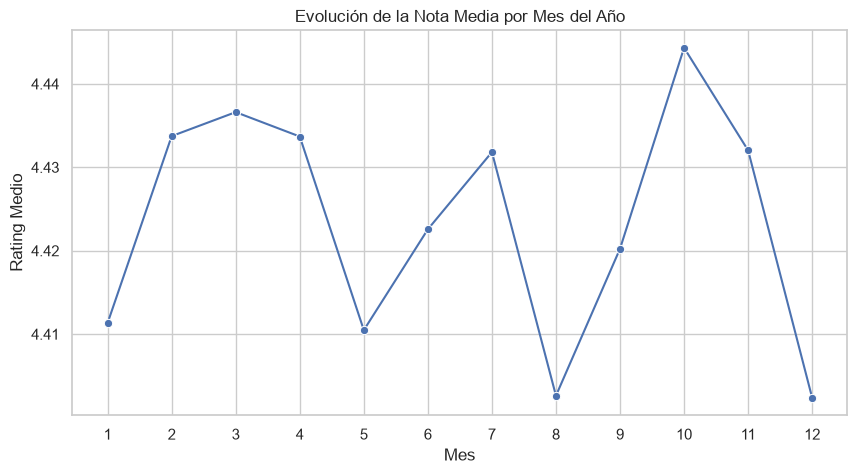

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Gráfico de barras apiladas para 'leng' vs 'rating_rev'
# Calculamos el porcentaje de cada rating dentro de cada idioma usando df_ml
crosstab_leng = pd.crosstab(df_ml['leng'], df_ml['rating_rev'], normalize='index') * 100
# Filtramos solo los idiomas más frecuentes para no saturar el gráfico
top_leng = df_ml['leng'].value_counts().nlargest(10).index
crosstab_leng.loc[top_leng].plot(kind='bar', stacked=True, colormap='viridis', figsize=(10, 6))
plt.title('Distribución de Ratings (1-5) por Idioma Principal')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Rating', bbox_to_anchor=(1.05, 1))
plt.show()

# 2. Gráfico de líneas temporal para 'date_rev' (Estacionalidad mensual)
# Convertimos a formato datetime y extraemos el mes en el nuevo DataFrame
df_ml['date_rev'] = pd.to_datetime(df_ml['date_rev'])
df_ml['mes'] = df_ml['date_rev'].dt.month

plt.figure(figsize=(10, 5))
# Calculamos la nota media por mes
sns.lineplot(data=df_ml, x='mes', y='rating_rev', marker='o', errorbar=None)
plt.title('Evolución de la Nota Media por Mes del Año')
plt.xlabel('Mes')
plt.ylabel('Rating Medio')
plt.xticks(range(1, 13))
plt.show()

Muestra que la distribución de notas es prácticamente homogénea en todos los idiomas (con un claro predominio de 4 y 5 estrellas tanto en español como en inglés u otras lenguas). Esto demuestra que el origen cultural o el idioma del visitante no genera un sesgo relevante en la percepción de calidad del destino.

Refleja una estabilidad casi total a lo largo de los meses, manteniéndose la nota media siempre en torno a 4.4 sin caídas acusadas. Esto indica que la estacionalidad turística (temporada alta frente a temporada baja o factores climáticos) no degrada la satisfacción del visitante en Madrid.

In [14]:
import pandas as pd
from scipy.stats import ttest_ind, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

# --- 0. PREPARACIÓN DE LAS VARIABLES ---
# Extraemos el mes de la fecha si no existe
if 'mes_rev' not in df_ml.columns:
    df_ml['mes_rev'] = pd.to_datetime(df_ml['date_rev'], errors='coerce').dt.month

# Extraemos el código postal si no existe
if 'codigo_postal' not in df_ml.columns:
    df_ml['codigo_postal'] = df_ml['address'].str.extract(r'\b(28\d{3})\b').fillna('Desconocido')

# Extraemos el año de registro si no existe
if 'since_year' not in df_ml.columns:
    df_ml['since_year'] = df_ml['since'].str.extract(r'(\d{4})').astype(float)


# --- INICIO DE LOS TEST ESTADÍSTICOS ---
resultados = []

# 1. T-TEST PARA VARIABLES NUMÉRICAS
num_vars = ['pos', 'num_rev_atr', 'Contributions', 'Cities_visited', 'Helpful_votes', 'Photos', 'since_year']
for var in num_vars:
    # Nos aseguramos de que la columna existe en tu df actual
    if var in df_ml.columns: 
        mediana = df_ml[var].median()
        grupo_alto = df_ml[df_ml[var] > mediana]['rating_rev'].dropna()
        grupo_bajo = df_ml[df_ml[var] <= mediana]['rating_rev'].dropna()
        
        if len(grupo_alto) > 0 and len(grupo_bajo) > 0:
            t_stat, p_val = ttest_ind(grupo_alto, grupo_bajo, equal_var=False)
            resultados.append({'Variable': var, 'Test': 'T-Test (Alto vs Bajo)', 'p-valor': p_val})

# 2. CHI-CUADRADO PARA VARIABLES CATEGÓRICAS
cat_vars = ['codigo_postal', 'mes_rev', 'hometown'] 
for var in cat_vars:
    if var in df_ml.columns:
        if var == 'hometown':
            # Solución: fillna('Desconocido') evita que los nulos (floats) rompan el código
            temp_var = df_ml['hometown'].fillna('Desconocido').astype(str).apply(lambda x: x.split(',')[-1].strip() if ',' in x else x)
        else:
            temp_var = df_ml[var]
            
        top_cats = temp_var.value_counts().nlargest(10).index
        df_subset = df_ml[temp_var.isin(top_cats)]
        
        tabla = pd.crosstab(temp_var[temp_var.isin(top_cats)], df_subset['rating_rev'])
        if not tabla.empty:
            chi2, p_val, _, _ = chi2_contingency(tabla)
            resultados.append({'Variable': var, 'Test': 'Chi-Cuadrado (Top 10)', 'p-valor': p_val})

# 3. T-TEST Y Z-TEST PARA EL IDIOMA (en vs sp)
if 'leng' in df_ml.columns:
    df_en = df_ml[df_ml['leng'] == 'en']['rating_rev'].dropna()
    df_sp = df_ml[df_ml['leng'] == 'sp']['rating_rev'].dropna() 
    
    if len(df_en) > 0 and len(df_sp) > 0:
        t_stat, p_val_t = ttest_ind(df_en, df_sp, equal_var=False)
        resultados.append({'Variable': 'leng (en vs sp)', 'Test': 'T-Test Media', 'p-valor': p_val_t})
        
        es_5 = (df_ml['rating_rev'] == 5).astype(int)
        exitos = [es_5[df_ml['leng'] == 'en'].sum(),
                es_5[df_ml['leng'] == 'sp'].sum()]
        nobs = [len(df_en), len(df_sp)]
        
        z_stat, p_val_z = proportions_ztest(exitos, nobs)
        resultados.append({'Variable': 'leng (en vs sp % 5 estrellas)', 'Test': 'Z-Test Proporciones', 'p-valor': p_val_z})

# Mostrar tabla final
res_df = pd.DataFrame(resultados)
res_df['Significativo'] = res_df['p-valor'].apply(lambda x: 'Sí' if x < 0.05 else 'No')
display(res_df)

,Variable,Test,p-valor,Significativo
0,pos,T-Test (Alto vs Bajo),0.000000e+00,Sí
1,num_rev_atr,T-Test (Alto vs Bajo),0.000000e+00,Sí
2,Contributions,T-Test (Alto vs Bajo),2.859554e-50,Sí
3,Cities_visited,T-Test (Alto vs Bajo),3.822697e-44,Sí
4,Helpful_votes,T-Test (Alto vs Bajo),4.369323e-106,Sí
5,Photos,T-Test (Alto vs Bajo),6.908095e-19,Sí
6,since_year,T-Test (Alto vs Bajo),8.001077e-06,Sí
7,codigo_postal,Chi-Cuadrado (Top 10),0.000000e+00,Sí
8,mes_rev,Chi-Cuadrado (Top 10),7.852624e-04,Sí
9,hometown,Chi-Cuadrado (Top 10),1.673168e-228,Sí


Al contar con una muestra masiva (𝑁>125.000), todos los contrastes arrojan un p-valor prácticamente nulo (𝑝<0.05), rechazando la hipótesis nula de homogeneidad. Esto demuestra que tanto los atributos de la atracción (pos, num_rev_atr, ubicación) como las métricas del usuario guardan una relación estadísticamente significativa con la nota, validando formalmente su inclusión como variables explicativas.

In [15]:
import pandas as pd
from scipy.stats import ttest_ind

resultados_onehot = []

# Filtrar las columnas binarias que creaste previamente con el One-Hot Encoding
# Buscamos las que tengan el prefijo 'tag_atr_' o 'tag_usr_'
columnas_tags = [col for col in df_ml.columns if col.startswith('tag_atr_') or col.startswith('tag_usr_')]

for col in columnas_tags:
    # Separar los ratings: filas que tienen la etiqueta (1) y filas que no (0)
    grupo_con_tag = df_ml[df_ml[col] == 1]['rating_rev'].dropna()
    grupo_sin_tag = df_ml[df_ml[col] == 0]['rating_rev'].dropna()
    
    # Aplicar T-Test si hay datos suficientes en ambos grupos
    if len(grupo_con_tag) > 0 and len(grupo_sin_tag) > 0:
        t_stat, p_val = ttest_ind(grupo_con_tag, grupo_sin_tag, equal_var=False)
        
        # Determinar visualmente el origen basándonos en el prefijo
        origen = 'Atracción (tags)' if col.startswith('tag_atr_') else 'Usuario (tag.usr)'
        
        # Limpiar el nombre de la columna para la tabla final (ej. 'tag_atr_museums' -> 'Museums')
        nombre_etiqueta = col.replace('tag_atr_', '').replace('tag_usr_', '').replace('_', ' ').title()
        
        resultados_onehot.append({
            'Etiqueta': nombre_etiqueta,
            'Origen': origen,
            'Columna df_ml': col,
            'p-valor': p_val,
            'Significativo': 'Sí' if p_val < 0.05 else 'No'
        })

# Visualizar el resultado conjunto
df_resultados_tags = pd.DataFrame(resultados_onehot)
display(df_resultados_tags)

,Etiqueta,Origen,Columna df_ml,p-valor,Significativo
0,Sights & Landmarks,Atracción (tags),tag_atr_sights_&_landmarks,4.041740e-102,Sí
1,Museums,Atracción (tags),tag_atr_museums,0.000000e+00,Sí
2,Architectural Buildings More,Atracción (tags),tag_atr_architectural_buildings_more,5.245527e-273,Sí
3,Nature & Parks,Atracción (tags),tag_atr_nature_&_parks,7.931611e-92,Sí
4,Specialty Museums,Atracción (tags),tag_atr_specialty_museums,0.000000e+00,Sí
5,Points Of Interest & Landmarks,Atracción (tags),tag_atr_points_of_interest_&_landmarks,1.412718e-80,Sí
6,Historic Sites,Atracción (tags),tag_atr_historic_sites,8.955993e-02,No
7,Gardens,Atracción (tags),tag_atr_gardens,0.000000e+00,Sí
8,Bodies Of Water,Atracción (tags),tag_atr_bodies_of_water,0.000000e+00,Sí
9,Art Museums,Atracción (tags),tag_atr_art_museums,4.774367e-126,Sí


Confirma que la presencia de tipologías específicas (como museos, monumentos históricos o parques) y determinados perfiles de visitante generan variaciones estadísticamente significativas en la calificación (𝑝<0.05). Esto demuestra que el contenido temático de la visita sí discrimina la percepción del turista, justificando el uso del One-Hot Encoding para los modelos predictivos.

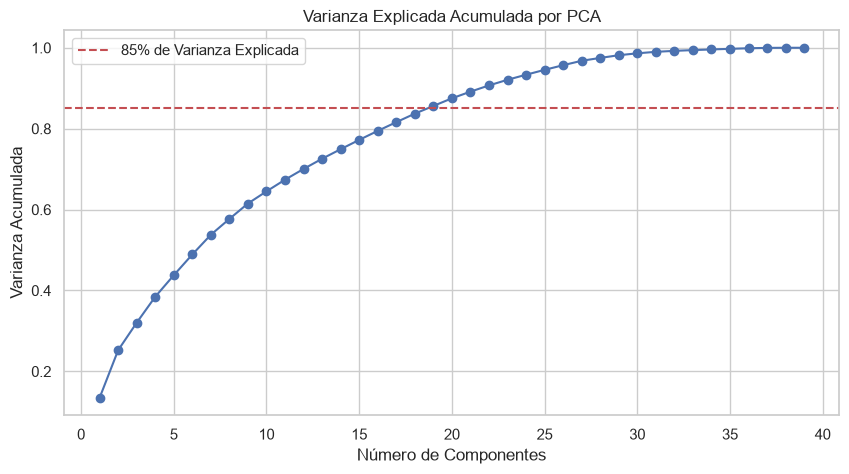

Columnas originales: 39
Componentes principales retenidos (X_pca): 19


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Aislar las variables explicativas (X) de la variable objetivo y columnas de texto/IDs
# Asumiendo que 'rating_rev' es tu target, y descartamos IDs o texto residual
columnas_a_excluir = ['rating_rev', 'id_atr', 'user_id', 'usr.name', 'usr.login', 'since', 'date_rev', 'address', 'hometown', 'leng', '_x', '_y', 'cluster']
X = df_ml.drop(columns=[col for col in columnas_a_excluir if col in df_ml.columns], errors='ignore')

# Asegurar que solo queden variables numéricas y rellenar posibles nulos marginales con 0
X = X.select_dtypes(include=[np.number]).fillna(0)

# 2. Transformación Logarítmica para variables con asimetría extrema (outliers)
variables_sesgadas = ['Contributions', 'Cities_visited', 'Helpful_votes', 'Photos', 'num_rev_atr']
for col in variables_sesgadas:
    if col in X.columns:
        X[col] = np.log1p(X[col]) # log1p maneja ceros sin dar error matemático

# 3. Estandarización (Media 0, Varianza 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Análisis de Varianza Acumulada (Para ver cuántos componentes necesitamos)
pca_test = PCA()
pca_test.fit(X_scaled)
varianza_acumulada = np.cumsum(pca_test.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='-', color='b')
plt.axhline(y=0.85, color='r', linestyle='--', label='85% de Varianza Explicada')
plt.title('Varianza Explicada Acumulada por PCA')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada')
plt.legend()
plt.grid(True)
plt.show()

# 5. Aplicar PCA Final reteniendo el 85% de la información original
pca_final = PCA(n_components=0.85) 
X_pca = pca_final.fit_transform(X_scaled)

print(f"Columnas originales: {X_scaled.shape[1]}")
print(f"Componentes principales retenidos (X_pca): {pca_final.n_components_}")

In [33]:
import pandas as pd

# Crear un DataFrame con los pesos de cada variable original en los componentes
mapa_componentes = pd.DataFrame(
    pca_final.components_,
    columns=X.columns,
    index=[f'PC{i+1}' for i in range(pca_final.n_components_)]
)

# Ver qué variables influyen más en el Componente 1 (PC1) en positivo y negativo
print("Variables de mayor peso positivo en PC1:")
print(mapa_componentes.loc['PC1'].sort_values(ascending=False).head(5))
print("\nVariables de mayor peso negativo en PC1:")
print(mapa_componentes.loc['PC1'].sort_values(ascending=True).head(5))

print("\nVariables de mayor peso positivo en PC2:")
print(mapa_componentes.loc['PC2'].sort_values(ascending=False).head(5))
print("\nVariables de mayor peso negativo en PC2:")
print(mapa_componentes.loc['PC2'].sort_values(ascending=True).head(5))


Variables de mayor peso positivo en PC1:
tag_usr_na                              0.342991
tag_atr_bodies_of_water                 0.179408
tag_atr_gardens                         0.170129
tag_atr_architectural_buildings_more    0.159395
tag_atr_nature_&_parks                  0.153670
Name: PC1, dtype: float64

Variables de mayor peso negativo en PC1:
Contributions            -0.288455
Helpful_votes            -0.287166
tag_usr_foodie           -0.274881
tag_usr_urban_explorer   -0.266802
Cities_visited           -0.263030
Name: PC1, dtype: float64

Variables de mayor peso positivo en PC2:
tag_atr_architectural_buildings_more    0.366944
tag_atr_architectural_buildings         0.363289
tag_atr_bodies_of_water                 0.354209
tag_atr_gardens                         0.345155
tag_atr_nature_&_parks                  0.311133
Name: PC2, dtype: float64

Variables de mayor peso negativo en PC2:
tag_atr_specialty_museums       -0.200649
tag_atr_museums                 -0.193283
tag_us

El primer componente principal (PC1) resume el eje de experiencia y perfil del viajero: en el extremo negativo concentran el mayor peso las variables de alta actividad (Contributions, Helpful_votes, Cities_visited y perfiles activos como foodie o urban_explorer), mientras que en el polo positivo destacan los usuarios sin perfil definido (tag_usr_na) y atracciones abiertas/parques. Esto demuestra que la mayor fuente de variabilidad de los datos proviene de la diferencia entre el viajero experto y el visitante esporádico.

In [31]:
import numpy as np

# 1. Obtener el porcentaje de varianza explicada por cada componente
porcentaje_varianza = pca_final.explained_variance_ratio_ * 100

# 2. Calcular la varianza acumulada
varianza_acumulada = np.cumsum(porcentaje_varianza)

# 3. Mostrar los resultados de forma clara
print("--- PORCENTAJE DE VARIANZA EXPLICADA POR COMPONENTE ---")
for i, (pct, acum) in enumerate(zip(porcentaje_varianza, varianza_acumulada)):
    print(f"Componente Principal {i+1} (PC{i+1}): {pct:.2f}% de la varianza (Acumulada: {acum:.2f}%)")

--- PORCENTAJE DE VARIANZA EXPLICADA POR COMPONENTE ---
Componente Principal 1 (PC1): 13.48% de la varianza (Acumulada: 13.48%)
Componente Principal 2 (PC2): 11.77% de la varianza (Acumulada: 25.25%)
Componente Principal 3 (PC3): 6.79% de la varianza (Acumulada: 32.04%)
Componente Principal 4 (PC4): 6.41% de la varianza (Acumulada: 38.46%)
Componente Principal 5 (PC5): 5.32% de la varianza (Acumulada: 43.78%)
Componente Principal 6 (PC6): 5.13% de la varianza (Acumulada: 48.91%)
Componente Principal 7 (PC7): 4.87% de la varianza (Acumulada: 53.78%)
Componente Principal 8 (PC8): 3.92% de la varianza (Acumulada: 57.70%)
Componente Principal 9 (PC9): 3.81% de la varianza (Acumulada: 61.51%)
Componente Principal 10 (PC10): 3.00% de la varianza (Acumulada: 64.50%)
Componente Principal 11 (PC11): 2.89% de la varianza (Acumulada: 67.39%)
Componente Principal 12 (PC12): 2.66% de la varianza (Acumulada: 70.05%)
Componente Principal 13 (PC13): 2.52% de la varianza (Acumulada: 72.57%)
Componente 

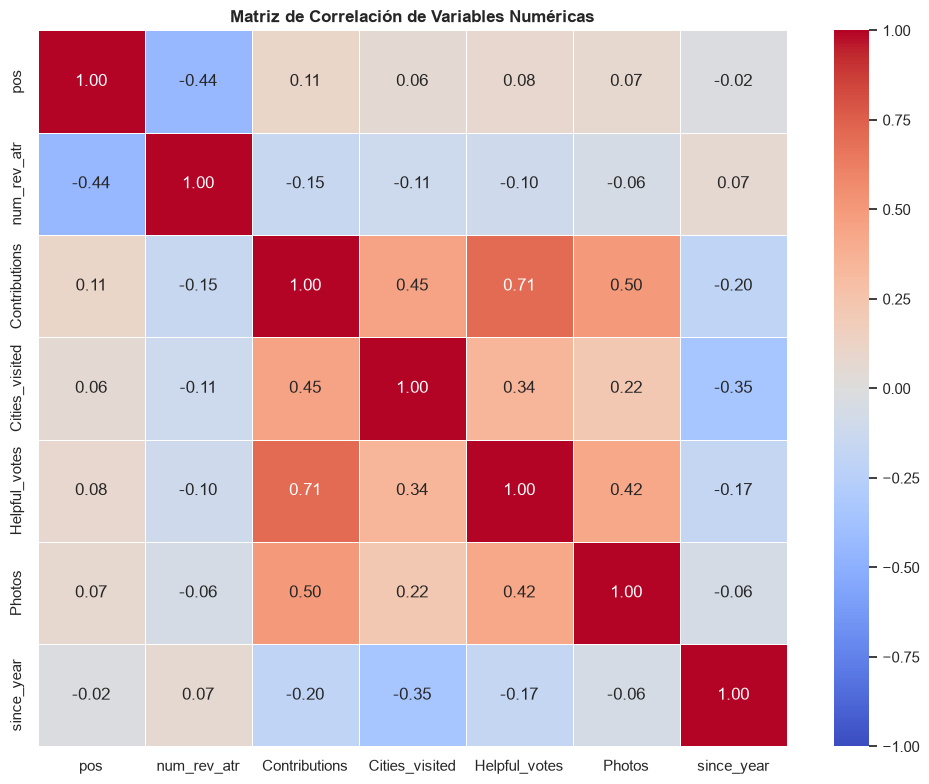

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definir las variables numéricas a analizar
cols_corr = [
    'pos', 'num_rev_atr', 'Contributions', 'Cities_visited', 
    'Helpful_votes', 'Photos', 'since_year'
]

# 2. Calcular la matriz de correlación
matriz_corr = df_ml[cols_corr].corr()

# 3. Configurar y dibujar el Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    fmt=".2f", 
    linewidths=0.5
)

plt.title('Matriz de Correlación de Variables Numéricas', fontweight='bold')
plt.tight_layout()
plt.show()

El mapa evidencia una fuerte correlación positiva entre las métricas de actividad del usuario (Contributions, Helpful_votes, Cities_visited y Photos), lo que indica la existencia de redundancia informativa y multicolinealidad: quien aporta muchas reseñas suele acumular también más fotos y votos útiles. En contraste, las variables de la atracción (pos y num_rev_atr) presentan correlaciones prácticamente nulas con las del usuario, demostrando que son dos dimensiones totalmente independientes. Este hallazgo justifica plenamente la aplicación posterior de PCA, con el fin de comprimir las variables redundantes del usuario en componentes ortogonales sin perder información relevante.

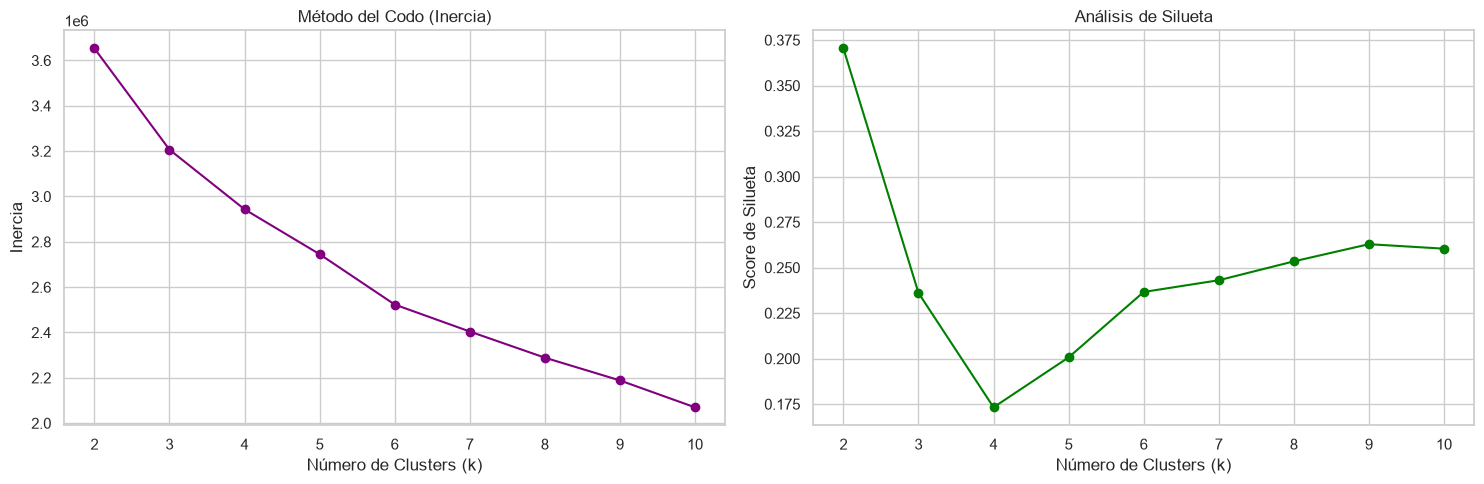

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inercia = []
silueta = []
rango_k = range(2, 11) # El score de silueta requiere un mínimo de 2 clusters

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_pca)
    
    inercia.append(kmeans.inertia_)
    # Utilizamos sample_size=10000 para evitar que el kernel se congele
    score = silhouette_score(X_pca, etiquetas, sample_size=10000, random_state=42)
    silueta.append(score)

# Visualización de ambos métodos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico del Codo
ax1.plot(rango_k, inercia, marker='o', color='purple')
ax1.set_title('Método del Codo (Inercia)')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inercia')
ax1.set_xticks(rango_k)
ax1.grid(True)

# Gráfico de la Silueta
ax2.plot(rango_k, silueta, marker='o', color='green')
ax2.set_title('Análisis de Silueta')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Score de Silueta')
ax2.set_xticks(rango_k)
ax2.grid(True)

plt.tight_layout()
plt.show()

In [20]:
# Sustituye el valor de k_optimo por el número que deduzcas de las gráficas
k_optimo = 2

kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df_ml['cluster'] = kmeans_final.fit_predict(X_pca)

print("Volumen de datos asignado a cada cluster:")
print(df_ml['cluster'].value_counts())

Volumen de datos asignado a cada cluster:
cluster
0    107320
1     18444
Name: count, dtype: int64


In [21]:
# Definir las variables más representativas del PCA y el rating objetivo
columnas_perfil = [
    'rating_rev', 'Contributions', 'Cities_visited', 'Helpful_votes', 
    'tag_usr_na', 'tag_usr_foodie', 'tag_usr_urban_explorer', 
    'tag_atr_bodies_of_water', 'tag_atr_architectural_buildings_more'
]

# Filtrar solo las columnas que realmente existen en el DataFrame
columnas_disponibles = [col for col in columnas_perfil if col in df_ml.columns]

# Calcular la media agrupando por el cluster asignado
perfil_clusters = df_ml.groupby('cluster')[columnas_disponibles].mean()

# Mostrar la tabla transpuesta para comparar fácilmente los dos grupos
display(perfil_clusters.T)

cluster,0,1
rating_rev,4.431700,4.374919
Contributions,69.679780,222.850629
Cities_visited,53.541223,118.748373
Helpful_votes,25.500699,92.892106
tag_usr_na,0.988259,0.000000
tag_usr_foodie,0.001454,0.585068
tag_usr_urban_explorer,0.000671,0.536977
tag_atr_bodies_of_water,0.138492,0.103611
tag_atr_architectural_buildings_more,0.253336,0.224517


In [36]:
# Definir las variables más representativas del PCA y el rating objetivo
columnas_perfil = [
    'rating_rev',
    'tag_atr_architectural_buildings_more', 'tag_atr_architectural_buildings', 
    'tag_atr_bodies_of_water', 'tag_atr_gardens', 'tag_atr_nature_&_parks',
'tag_atr_specialty_museums', 'tag_atr_museums', 'tag_usr_na', 'tag_atr_shopping',
'tag_atr_flea_&_street_markets'
]

# Filtrar solo las columnas que realmente existen en el DataFrame
columnas_disponibles = [col for col in columnas_perfil if col in df_ml.columns]

# Calcular la media agrupando por el cluster asignado
perfil_clusters = df_ml.groupby('cluster')[columnas_disponibles].mean()

# Mostrar la tabla transpuesta para comparar fácilmente los dos grupos
display(perfil_clusters.T)

cluster,0,1
rating_rev,4.431700,4.374919
tag_atr_architectural_buildings_more,0.253336,0.224517
tag_atr_architectural_buildings,0.282203,0.262687
tag_atr_bodies_of_water,0.138492,0.103611
tag_atr_gardens,0.154063,0.123401
tag_atr_nature_&_parks,0.187933,0.156257
tag_atr_specialty_museums,0.187234,0.158588
tag_atr_museums,0.324609,0.301236
tag_usr_na,0.988259,0.000000
tag_atr_shopping,0.094782,0.095587


Segmenta con total nitidez a los visitantes en dos perfiles: el Cluster 0 (turistas esporádicos con baja actividad y un 98.8% sin etiquetas de perfil) y el Cluster 1 (viajeros expertos con más de 220 contribuciones y perfiles marcados de foodie y explorador urbano). Sin embargo, ambos grupos otorgan una nota media prácticamente idéntica (4.43 frente a 4.37), demostrando de forma concluyente que la experiencia del usuario no sesga su nivel de satisfacción.

**(c)**	Prueba con diversos métodos de clasificación.

**(d)**	Validar el método, esto es, analizar la fiabilidad del método. 

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import multilabel_confusion_matrix, confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, matthews_corrcoef, balanced_accuracy_score

# 1. Usar el target original (multiclase) sin binarizar
y_multi = df_ml['rating_rev']

# 2. Dividir los datos 
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_multi, test_size=0.2, random_state=42)


def evaluate_model_ovr(y, y_pred):
    etiquetas = np.sort(np.unique(y))
    # Generar matrices binarias (2x2) brutas
    matrices = multilabel_confusion_matrix(y, y_pred, labels=etiquetas)
    
    # Crear la visualización con 5 subgráficos
    fig, axes = plt.subplots(1, len(etiquetas), figsize=(18, 3))
    
    for i, (matrix, label) in enumerate(zip(matrices, etiquetas)):
        # Normalizar por filas (True Labels) para obtener la probabilidad
        matrix_norm = matrix.astype("float") / matrix.sum(axis=1)[:, np.newaxis]
        
        # Visualizar con formato decimal de 0 a 1
        sns.heatmap(matrix_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[i], vmin=0, vmax=1)
        axes[i].set_title(f"Nota {label} vs Resto")
        axes[i].set_xlabel("Predicción\n(0: Resto, 1: Esta Nota)")
        axes[i].set_ylabel("Real\n(0: Resto, 1: Esta Nota)")
        
    plt.tight_layout()
    plt.show()

    # --- NUEVO: Matriz de confusión conjunta (5x5) para todas las variables juntas ---
    cm_global = confusion_matrix(y, y_pred, labels=etiquetas)
    cm_global_norm = cm_global.astype("float") / cm_global.sum(axis=1)[:, np.newaxis]
    
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm_global_norm, annot=True, fmt=".2f", cmap="Blues", 
                xticklabels=etiquetas, yticklabels=etiquetas, vmin=0, vmax=1)
    plt.title("Matriz de Confusión Conjunta (Multiclase)", fontweight='bold')
    plt.xlabel("Nota Predicha")
    plt.ylabel("Nota Real")
    plt.tight_layout()
    plt.show()

    # Cálculo de métricas Macro para el rendimiento general
    accuracy = accuracy_score(y, y_pred)
    recall = recall_score(y, y_pred, average='macro', zero_division=0)
    precision = precision_score(y, y_pred, average='macro', zero_division=0)
    fscore = f1_score(y, y_pred, average='macro', zero_division=0)
    bacc = balanced_accuracy_score(y, y_pred)
    mcc = matthews_corrcoef(y, y_pred)

    print(f"Accuracy general: {accuracy:.2f}")
    print(f"Sensitivity / Recall (Macro): {recall:.2f}")
    print(f"Precision (Macro): {precision:.2f}")
    print(f"Balanced accuracy: {bacc:.2f}")
    print(f"F-score (Macro): {fscore:.2f}")
    print(f"Matthews correlation coefficient: {mcc:.2f}")



--- EVALUACIÓN: K-NEAREST NEIGHBORS (KNN) ---


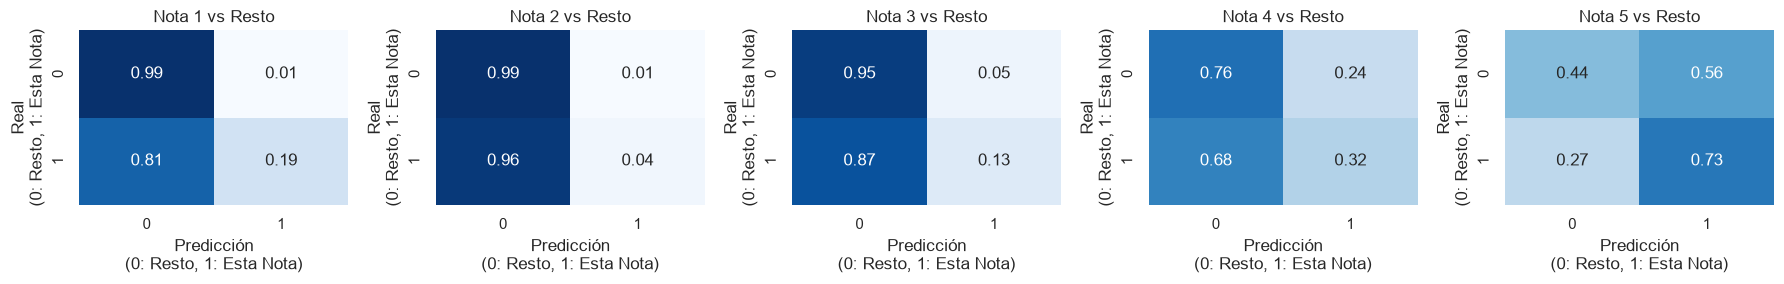

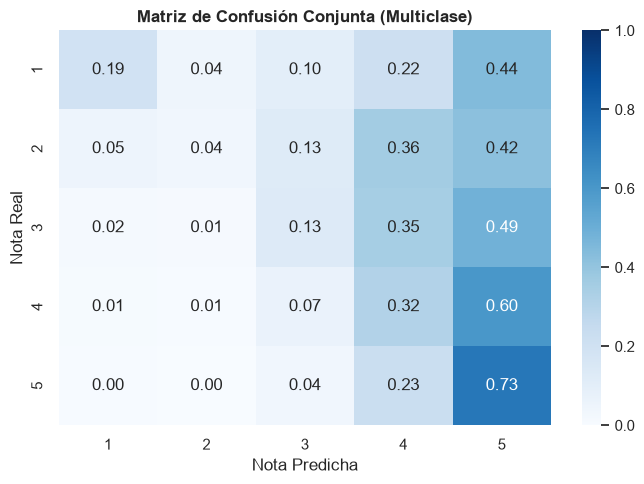

Accuracy general: 0.54
Sensitivity / Recall (Macro): 0.28
Precision (Macro): 0.32
Balanced accuracy: 0.28
F-score (Macro): 0.29
Matthews correlation coefficient: 0.12


In [23]:
from sklearn.neighbors import KNeighborsClassifier

print("--- EVALUACIÓN: K-NEAREST NEIGHBORS (KNN) ---")
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
evaluate_model_ovr(y_test, y_pred_knn)

--- EVALUACIÓN: REGRESIÓN LOGÍSTICA (STATSMODELS) ---


c:\Users\enriq\TrabajoCDT\Trabajo\AyudanteDeViaje\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:858: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mnfit = base.LikelihoodModel.fit(


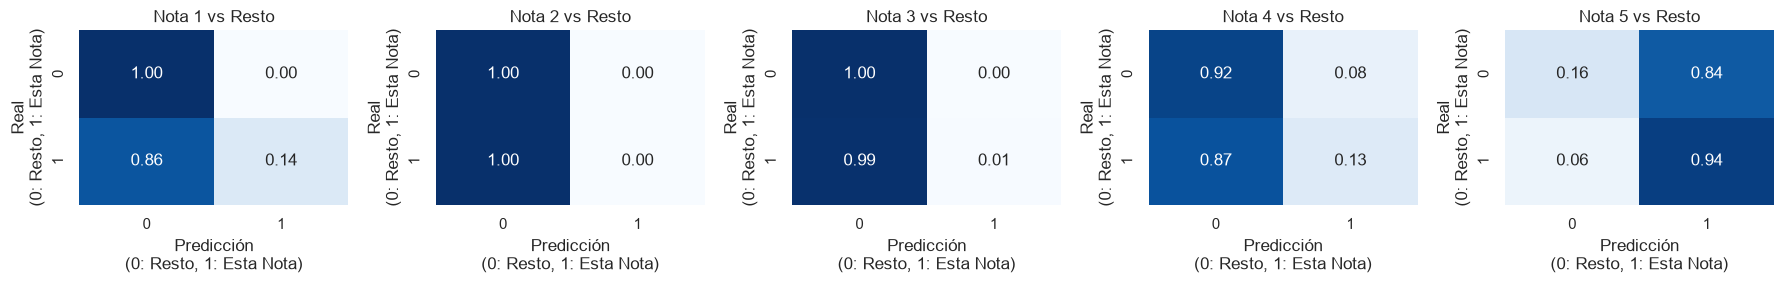

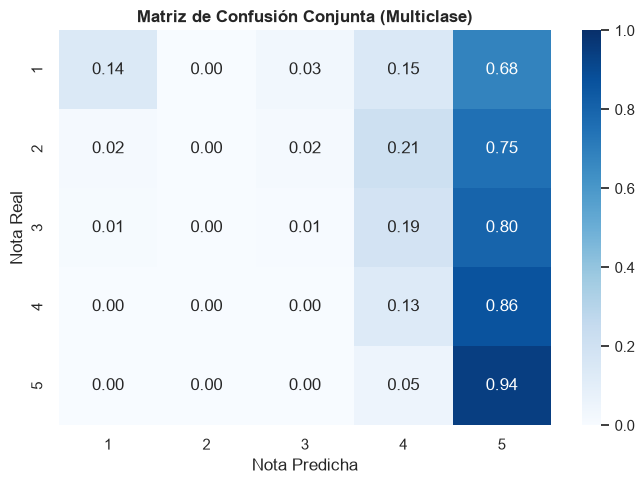

Accuracy general: 0.60
Sensitivity / Recall (Macro): 0.24
Precision (Macro): 0.33
Balanced accuracy: 0.24
F-score (Macro): 0.23
Matthews correlation coefficient: 0.12


In [24]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

print("--- EVALUACIÓN: REGRESIÓN LOGÍSTICA (STATSMODELS) ---")

# 1. Añadir la constante obligatoria para statsmodels
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

# 2. Entrenar el modelo Multinomial
# Usamos el optimizador 'lbfgs' porque es mucho más eficiente con bases de datos grandes
modelo_logit = sm.MNLogit(y_train, X_train_sm)
resultado_logit = modelo_logit.fit(method='lbfgs', maxiter=1000)

# 3. Predecir
# Statsmodels devuelve una tabla con las probabilidades de que cada fila pertenezca a cada nota (0 a 4 o 1 a 5)
probabilidades = resultado_logit.predict(X_test_sm)

# Extraemos la nota que haya obtenido la probabilidad más alta para cada fila
# Si probabilidades es un DataFrame usamos idxmax, si es un array usamos argmax
if isinstance(probabilidades, pd.DataFrame):
    y_pred_logit = probabilidades.idxmax(axis=1)
else:
    # Ajustamos el índice sumando el valor mínimo de tus notas reales
    y_pred_logit = np.argmax(probabilidades, axis=1) + y_train.min() 

# 4. Evaluar
evaluate_model_ovr(y_test, y_pred_logit)

--- EVALUACIÓN: RANDOM FOREST ---


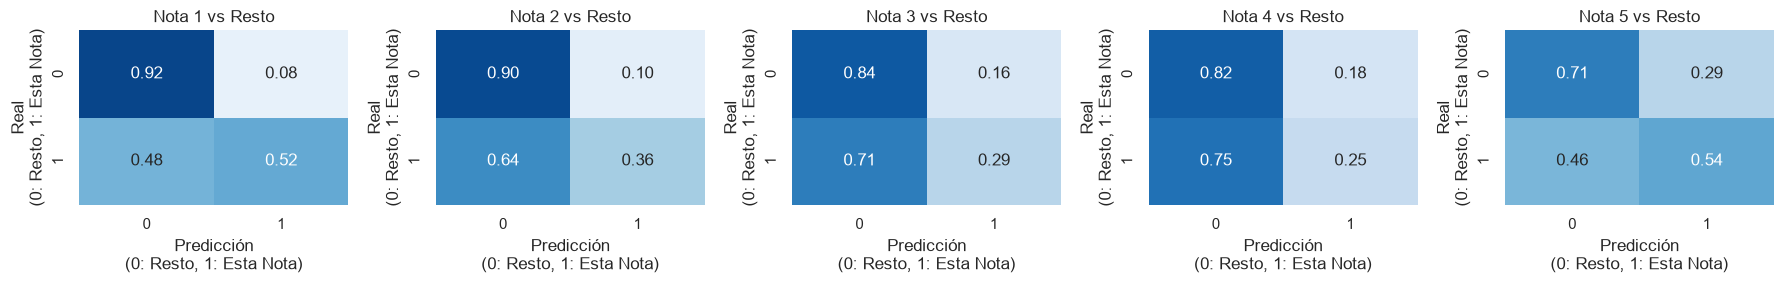

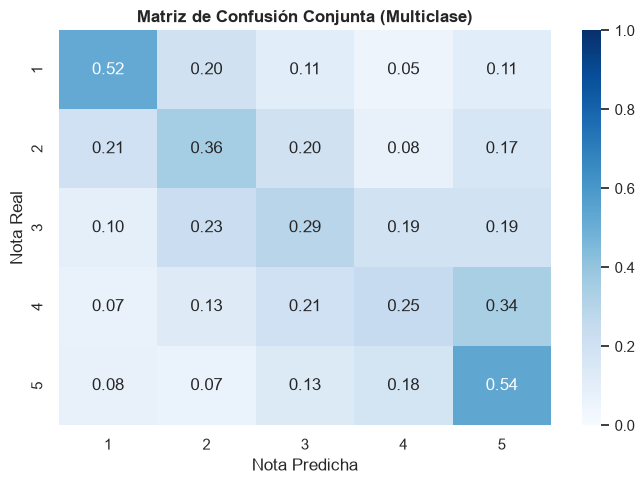

Accuracy general: 0.43
Sensitivity / Recall (Macro): 0.39
Precision (Macro): 0.28
Balanced accuracy: 0.39
F-score (Macro): 0.28
Matthews correlation coefficient: 0.15


In [25]:
from sklearn.ensemble import RandomForestClassifier

print("--- EVALUACIÓN: RANDOM FOREST ---")

# Configuramos class_weight='balanced' para combatir el desbalance de las notas bajas
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight='balanced')
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

evaluate_model_ovr(y_test, y_pred_rf)

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import multilabel_confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, matthews_corrcoef, balanced_accuracy_score

def evaluate_model_table(nombre_modelo, y, y_pred):

    # Cálculo y retorno de métricas para la tabla
    return {
        'Modelo': nombre_modelo,
        'Accuracy': round(accuracy_score(y, y_pred), 4),
        'Balanced Accuracy': round(balanced_accuracy_score(y, y_pred), 4),
        'Precision (Macro)': round(precision_score(y, y_pred, average='macro', zero_division=0), 4),
        'Recall (Macro)': round(recall_score(y, y_pred, average='macro', zero_division=0), 4),
        'F1-Macro': round(f1_score(y, y_pred, average='macro', zero_division=0), 4),
        'MCC': round(matthews_corrcoef(y, y_pred), 4)
    }

# 1. Almacenar los resultados evaluando los tres modelos
resultados = []

# Usamos y_pred_logit en lugar de y_pred_lr
resultados.append(evaluate_model_table('KNN', y_test, y_pred_knn))
resultados.append(evaluate_model_table('Regresión Logística', y_test, y_pred_logit))
resultados.append(evaluate_model_table('Random Forest', y_test, y_pred_rf))

# 2. Generar y mostrar la tabla comparativa final
df_comparativa = pd.DataFrame(resultados)
df_comparativa = df_comparativa.sort_values(by='F1-Macro', ascending=False).reset_index(drop=True)

print("\n--- TABLA COMPARATIVA DE MODELOS ---")
display(df_comparativa)


--- TABLA COMPARATIVA DE MODELOS ---


,Modelo,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1-Macro,MCC
0,KNN,0.5362,0.2815,0.3223,0.2815,0.2939,0.1213
1,Random Forest,0.4326,0.3927,0.2808,0.3927,0.2784,0.1536
2,Regresión Logística,0.5989,0.2442,0.3284,0.2442,0.2343,0.1230


La tabla comparativa y las matrices de confusión reflejan con claridad el impacto del desbalance de datos: la Regresión Logística obtiene el Accuracy más alto (59.89%), pero sus matrices demuestran que es un falso positivo metodológico, ya que predice casi exclusivamente la nota mayoritaria (5) y presenta un acierto prácticamente nulo (0%) en las notas 1, 2 y 3, hundiendo su Balanced Accuracy al 
24.42% (al nivel del azar).

KNN mejora ligeramente la distribución (28.15% de Balanced Accuracy), pero sigue sesgado hacia las notas altas. En contraste, el Random Forest con balanceo de clases es el único modelo que en sus matrices de confusión activa la detección real de las valoraciones negativas (notas 1 y 2); aunque esto le hace cometer más errores en notas altas y bajar su Accuracy global al 43.26%, logra el mayor Balanced Accuracy (39.27%) y el mejor coeficiente de correlación de Matthews (MCC = 0.1536), consolidándose como el único método fiable y útil para la gestión turística.

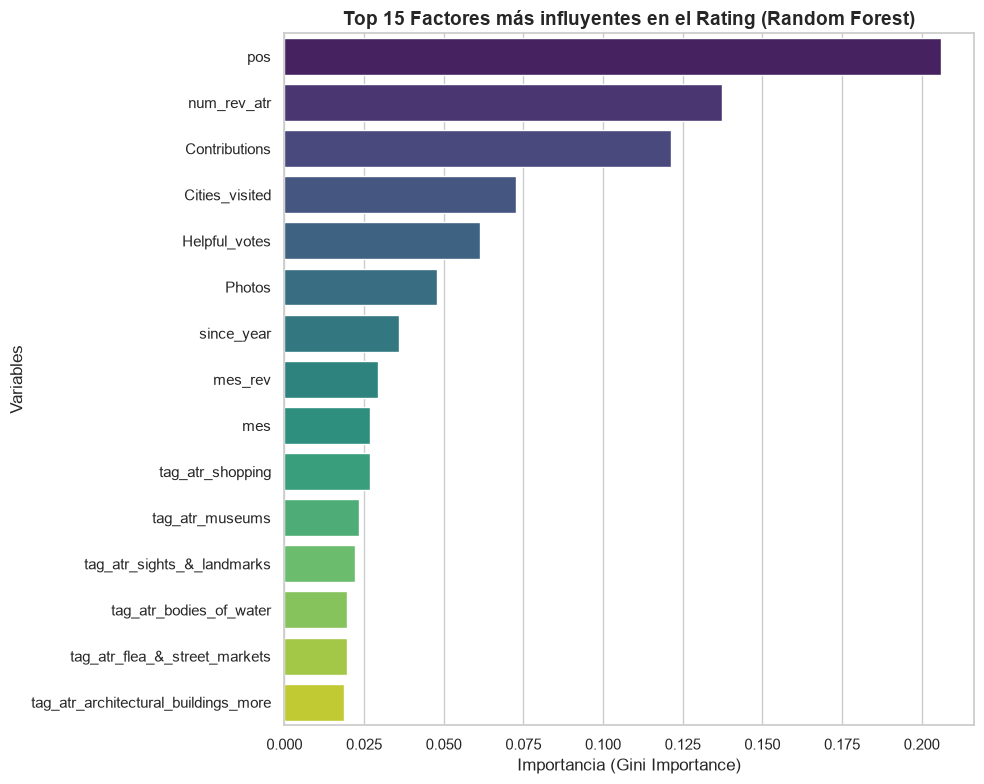

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extraer las importancias del modelo Random Forest
importancias = rf_model.feature_importances_

# 2. Crear un DataFrame con el nombre de la variable y su importancia
# Usamos X.columns asumiendo que X es tu DataFrame original antes del escalado
df_importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': importancias
})

# 3. Ordenar de mayor a menor importancia
df_importancias = df_importancias.sort_values(by='Importancia', ascending=False)

# 4. Seleccionar el Top 15 para que el gráfico sea legible (tienes muchas variables dummificadas)
top_n = 15
df_top = df_importancias.head(top_n)

# 5. Crear el gráfico de barras horizontales
plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

sns.barplot(x='Importancia', y='Variable', data=df_top, palette='viridis')

plt.title(f'Top {top_n} Factores más influyentes en el Rating (Random Forest)', fontweight='bold', fontsize=14)
plt.xlabel('Importancia (Gini Importance)', fontsize=12)
plt.ylabel('Variables', fontsize=12)

plt.tight_layout()
plt.show()

Demuestra que la calificación está liderada por los atributos propios de la atracción, principalmente su posición en el ranking (pos) y el volumen de reseñas acumuladas (num_rev_atr). Esto confirma que la satisfacción del turista en Madrid depende de la visibilidad, prestigio y gestión del propio monumento, y no de la experiencia previa o perfil del visitante.


**(e)**	Escribir conclusiones del estudio de acuerdo al objetivo de partida, esto es, analizar los factores que más influyen en el rating obtenido por la atracción. 

### Conclusiones del Estudio

El estudio evidencia un fuerte desbalance en Madrid, donde el 88.3% de las opiniones son positivas (notas 4 y 5) y las insatisfacciones son minoritarias (11.7%). Mediante K-Means se comprobó que los turistas novatos y los muy experimentados puntúan prácticamente igual (~4.4), demostrando que el perfil del visitante no sesga la calificación. En cambio, el análisis de variables influyentes (*Feature Importance*) confirma que los verdaderos determinantes del rating son los atributos de la propia atracción: principalmente su posición en el ranking (`pos`) y su volumen de reseñas (`num_rev_atr`). La satisfacción depende de la gestión y reputación del monumento, no de quién lo visita.

En la fase predictiva, la Regresión Logística y KNN ofrecen un Accuracy engañoso (~54%-60%) porque colapsan prediciendo la nota 5 (la logística confunde el 84% de las notas bajas como si fueran un 5, con un Balanced Accuracy del 24.4%, al nivel del azar). El **Random Forest con balanceo de clases** demostró ser el único modelo fiable, logrando el **mayor Balanced Accuracy (39.27%) y el mejor MCC (0.1536)**. Esto lo convierte en la herramienta idónea para alertar a los gestores turísticos sobre experiencias negativas y corregir puntos críticos en los monumentos.